# Analytical validation — synthetic data

This is an offline software demonstration, **not an F1 session or evidence about any driver**. Two constant-speed laps cover 1 km: 180 km/h takes 20 s and 144 km/h takes 25 s. The expected final gap is +5 s. Different sample spacings test the shared-distance alignment.

In [1]:
from pathlib import Path
import os
if Path.cwd().name == 'notebooks':
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from f1_analyser.analysis import compare_laps

def synthetic_lap(speed, count):
    distance = np.linspace(0, 1000, count)
    return pd.DataFrame(dict(Distance=distance, Time=distance / (speed / 3.6),
                             Speed=speed, Throttle=100, Brake=False, nGear=7))
reference, comparison = synthetic_lap(180, 101), synthetic_lap(144, 81)
result = compare_laps(reference, comparison, 20, 25)
print(f'Expected +5.000 s; measured {result.estimated_gap:+.3f} s')
assert np.isclose(result.estimated_gap, 5)
assert np.allclose(compare_laps(reference, reference, 20, 20).aligned.Delta, 0)
assert np.allclose(result.aligned.Delta, -compare_laps(comparison, reference, 25, 20).aligned.Delta)
print('Analytical solution, self-comparison and sign reversal passed.')

Expected +5.000 s; measured +5.000 s
Analytical solution, self-comparison and sign reversal passed.


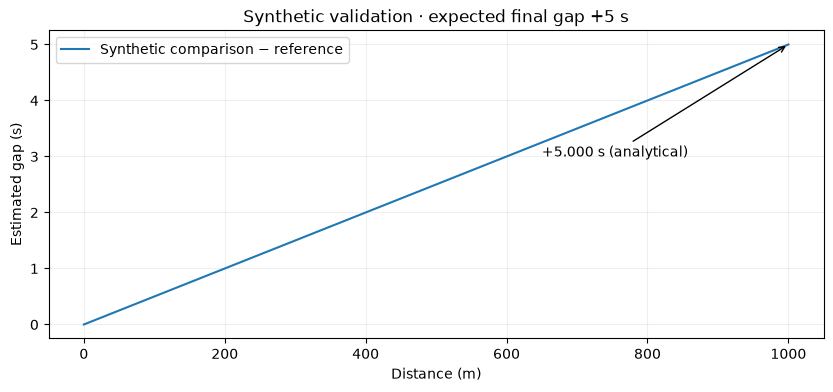

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(result.aligned.Distance, result.aligned.Delta, label='Synthetic comparison − reference')
ax.set(xlabel='Distance (m)', ylabel='Estimated gap (s)', title='Synthetic validation · expected final gap +5 s')
ax.annotate('+5.000 s (analytical)', xy=(1000, 5), xytext=(650, 3), arrowprops={'arrowstyle':'->'})
ax.legend(); ax.grid(alpha=0.2)
Path('reports').mkdir(exist_ok=True)
fig.savefig('reports/synthetic-validation.svg', bbox_inches='tight')
plt.show()

These checks establish software invariants, not historical accuracy. The estimated gap is integrated from speed; real timing must still be compared independently. Remaining tests exercise missing samples, invalid channels, discrete interpolation, filtering and the dashboard.